# Proyecto integrador: Análisis estadístico descriptivo y probabilístico

**Programa:** Técnico en Programación para Analítica de Datos  
**Grupo:**  3411643  
**Competencia:** Procesar datos de acuerdo con procedimiento técnico y metodología estadística  
**Duración sugerida:** 5-6 horas  
**Producto:** Notebook Jupyter `.ipynb`  
**Instructor:**  César Marino Cuéllar Chacón

## Situación problema
Una organización requiere analizar datos internacionales para identificar patrones mediante estadística descriptiva y probabilidad. El equipo deberá obtener datos externos, identificar y seleccionar variables, calcular medidas de tendencia central, dispersión y posición, calcular probabilidades marginales, conjuntas y condicionales, aplicar Bayes, visualizar resultados y elaborar un informe técnico.

## Objetivo general
Desarrollar un análisis estadístico descriptivo y probabilístico reproducible utilizando Python, datos externos y visualizaciones.

## Objetivos específicos
- Explorar y documentar una fuente de datos externa.
- Identificar y clasificar variables.
- Seleccionar variables y justificar su selección.
- Calcular media, mediana, moda, rango, varianza, desviación estándar y medidas de posición.
- Calcular probabilidades marginales, conjuntas y condicionales.
- Aplicar y validar el teorema de Bayes.
- Presentar resultados mediante gráficos.
- Elaborar conclusiones y un informe técnico.


# 1. Fuente de datos externa

Se utilizará el conjunto **Gapminder**, disponible en CSV:

`https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv`

Variables principales:
- `country`: país.
- `continent`: continente.
- `year`: año.
- `lifeExp`: esperanza de vida.
- `pop`: población.
- `gdpPercap`: PIB per cápita.

El notebook carga directamente el CSV desde la URL. Si el instructor utiliza otra fuente, el aprendiz puede reemplazar la URL y documentar su procedencia, fecha de consulta y características.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

URL_DATOS = "https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv"
df = pd.read_csv(URL_DATOS)

print("Dimensiones:", df.shape)
display(df.head())


Dimensiones: (1704, 6)


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


# 2. Identificación y selección de variables

Realice:
1. Identificación de nombres y tipos de datos.
2. Revisión de valores faltantes.
3. Revisión de duplicados.
4. Clasificación como cualitativa o cuantitativa.
5. Selección y justificación de variables.

Variables mínimas:
- `lifeExp`
- `pop`
- `gdpPercap`
- `continent`
- `country`

Cree además `nivel_vida`, usando la mediana de `lifeExp` del año seleccionado:
- Alta: `lifeExp >= mediana`
- Baja: `lifeExp < mediana`


In [2]:
df.info()
display(df.isna().sum().to_frame("faltantes"))
print("Duplicados:", df.duplicated().sum())

# Selección del año de análisis: se usa el año más reciente disponible (2007),
# porque ofrece la información más actualizada y comparable entre países.
anio_seleccionado = 2007
print("\nAños disponibles:", sorted(df["year"].unique()))
print("Año seleccionado:", anio_seleccionado)

# Dataframe auxiliar: se trabaja sobre una copia para no modificar el original "df"
dfp = df[df["year"] == anio_seleccionado].copy()
print("\nRegistros del año seleccionado:", dfp.shape)

# Clasificación de variables
clasificacion = pd.DataFrame({
    "variable": ["country", "continent", "year", "lifeExp", "pop", "gdpPercap"],
    "tipo_dato": [str(df[c].dtype) for c in ["country","continent","year","lifeExp","pop","gdpPercap"]],
    "clasificacion": ["Cualitativa nominal", "Cualitativa nominal", "Cuantitativa discreta",
                       "Cuantitativa continua", "Cuantitativa discreta", "Cuantitativa continua"]
})
display(clasificacion)

# Creación de nivel_vida a partir de la mediana de lifeExp del año seleccionado
mediana_lifeExp = dfp["lifeExp"].median()
dfp["nivel_vida"] = np.where(dfp["lifeExp"] >= mediana_lifeExp, "Alta", "Baja")

print(f"\nMediana de lifeExp en {anio_seleccionado}: {mediana_lifeExp:.2f} años")
display(dfp[["country","continent","lifeExp","nivel_vida"]].head())
print("\nDistribución de nivel_vida:")
display(dfp["nivel_vida"].value_counts())


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   year       1704 non-null   int64  
 2   pop        1704 non-null   float64
 3   continent  1704 non-null   str    
 4   lifeExp    1704 non-null   float64
 5   gdpPercap  1704 non-null   float64
dtypes: float64(3), int64(1), str(2)
memory usage: 80.0 KB


,faltantes
country,0
year,0
pop,0
continent,0
lifeExp,0
gdpPercap,0


Duplicados: 0

Años disponibles: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Año seleccionado: 2007

Registros del año seleccionado: (142, 6)


,variable,tipo_dato,clasificacion
0,country,str,Cualitativa nominal
1,continent,str,Cualitativa nominal
2,year,int64,Cuantitativa discreta
3,lifeExp,float64,Cuantitativa continua
4,pop,float64,Cuantitativa discreta
5,gdpPercap,float64,Cuantitativa continua



Mediana de lifeExp en 2007: 71.94 años


,country,continent,lifeExp,nivel_vida
11,Afghanistan,Asia,43.828,Baja
23,Albania,Europe,76.423,Alta
35,Algeria,Africa,72.301,Alta
47,Angola,Africa,42.731,Baja
59,Argentina,Americas,75.320,Alta



Distribución de nivel_vida:


nivel_vida
Baja    71
Alta    71
Name: count, dtype: int64

# 3. Medidas de tendencia central

Para `lifeExp`, `gdpPercap` y `pop` calcule:
- media;
- mediana;
- moda.

Interprete cada resultado y explique si media y mediana presentan diferencias importantes.

In [3]:
vars_num = ["lifeExp", "gdpPercap", "pop"]

def calcular_moda(serie):
    m = serie.mode()
    return m.iloc[0] if not m.empty else np.nan

tendencia = pd.DataFrame({
    "media": dfp[vars_num].mean(),
    "mediana": dfp[vars_num].median(),
    "moda": [calcular_moda(dfp[v]) for v in vars_num]
})
display(tendencia.round(2))

print(f"""
Interpretación:
- lifeExp: media ({tendencia.loc['lifeExp','media']:.2f}) y mediana ({tendencia.loc['lifeExp','mediana']:.2f})
  son cercanas, lo que indica una distribución relativamente simétrica de la esperanza de vida.
- gdpPercap: la media ({tendencia.loc['gdpPercap','media']:.2f}) es notablemente mayor que la mediana
  ({tendencia.loc['gdpPercap','mediana']:.2f}), lo que evidencia una distribución sesgada a la derecha:
  unos pocos países con PIB per cápita muy alto arrastran la media hacia arriba.
- pop: ocurre el mismo fenómeno, la media ({tendencia.loc['pop','media']:.2e}) es mucho mayor que la
  mediana ({tendencia.loc['pop','mediana']:.2e}) por la presencia de países muy poblados (outliers).
- La moda tiene poca utilidad interpretativa aquí porque son variables continuas con pocos valores repetidos.
""")


,media,mediana,moda
lifeExp,67.01,71.94,39.61
gdpPercap,11680.07,6124.37,277.55
pop,44021219.57,10517531.00,199579.00



Interpretación:
- lifeExp: media (67.01) y mediana (71.94)
  son cercanas, lo que indica una distribución relativamente simétrica de la esperanza de vida.
- gdpPercap: la media (11680.07) es notablemente mayor que la mediana
  (6124.37), lo que evidencia una distribución sesgada a la derecha:
  unos pocos países con PIB per cápita muy alto arrastran la media hacia arriba.
- pop: ocurre el mismo fenómeno, la media (4.40e+07) es mucho mayor que la
  mediana (1.05e+07) por la presencia de países muy poblados (outliers).
- La moda tiene poca utilidad interpretativa aquí porque son variables continuas con pocos valores repetidos.



# 4. Medidas de dispersión

Calcule para las variables numéricas:
- mínimo;
- máximo;
- rango;
- varianza;
- desviación estándar;
- coeficiente de variación.

Indique si está usando una estimación muestral o poblacional y mantenga la misma convención durante el análisis.

In [4]:
disp = pd.DataFrame(index=vars_num)
disp["minimo"] = dfp[vars_num].min()
disp["maximo"] = dfp[vars_num].max()
disp["rango"] = disp["maximo"] - disp["minimo"]

# Se utiliza la convención MUESTRAL (ddof=1), ya que los 142 países del año 2007
# se interpretan como una muestra de la población mundial de países.
disp["varianza"] = dfp[vars_num].var(ddof=1)
disp["desviacion_std"] = dfp[vars_num].std(ddof=1)
disp["coef_variacion_%"] = (disp["desviacion_std"] / dfp[vars_num].mean()) * 100

display(disp.round(2))

print("""
Interpretación:
- Se usa la desviación ESTÁNDAR MUESTRAL (ddof=1) de forma consistente en todo el análisis.
- lifeExp tiene un coeficiente de variación bajo (~18%): los países varían relativamente poco
  en esperanza de vida.
- gdpPercap y pop presentan coeficientes de variación muy altos (>100%), lo que confirma una
  dispersión enorme: hay países muy ricos/poblados junto a otros muy pobres/pequeños.
""")


,minimo,maximo,rango,varianza,desviacion_std,coef_variacion_%
lifeExp,39.61,8.260000e+01,4.299000e+01,1.457600e+02,1.207000e+01,18.02
gdpPercap,277.55,4.935719e+04,4.907964e+04,1.653780e+08,1.285994e+04,110.10
pop,199579.00,1.318683e+09,1.318484e+09,2.179208e+16,1.476214e+08,335.34



Interpretación:
- Se usa la desviación ESTÁNDAR MUESTRAL (ddof=1) de forma consistente en todo el análisis.
- lifeExp tiene un coeficiente de variación bajo (~18%): los países varían relativamente poco
  en esperanza de vida.
- gdpPercap y pop presentan coeficientes de variación muy altos (>100%), lo que confirma una
  dispersión enorme: hay países muy ricos/poblados junto a otros muy pobres/pequeños.



# 5. Medidas de posición y valores atípicos

Para `lifeExp` y `gdpPercap` calcule:
- Q1, Q2 y Q3;
- percentiles 10, 25, 50, 75 y 90;
- rango intercuartílico.

Identifique posibles valores atípicos de `gdpPercap` usando 1.5 × IQR.

Explique qué representan los resultados.

In [5]:
vars_pos = ["lifeExp", "gdpPercap"]
percentiles = [10, 25, 50, 75, 90]

posicion = pd.DataFrame(index=vars_pos)
for p in percentiles:
    posicion[f"P{p}"] = [np.percentile(dfp[v], p) for v in vars_pos]
posicion["IQR"] = posicion["P75"] - posicion["P25"]
display(posicion.round(2))

# Detección de atípicos en gdpPercap con la regla 1.5 * IQR
q1 = dfp["gdpPercap"].quantile(0.25)
q3 = dfp["gdpPercap"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = dfp[(dfp["gdpPercap"] < limite_inferior) | (dfp["gdpPercap"] > limite_superior)]
print(f"Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}")
print(f"Límite inferior: {limite_inferior:.2f}   Límite superior: {limite_superior:.2f}")
print(f"Cantidad de países atípicos en gdpPercap: {len(atipicos)} de {len(dfp)}")
display(atipicos[["country","continent","gdpPercap"]].sort_values("gdpPercap", ascending=False))

print("""
Interpretación:
- Q1 y Q3 de lifeExp muestran que el 50% central de los países tiene esperanza de vida
  entre ~57 y ~76 años.
- El IQR de gdpPercap es muy amplio, lo que confirma la alta dispersión ya vista.
- Los países atípicos por arriba corresponden a economías con PIB per cápita extremadamente alto
  (por ejemplo Kuwait, Noruega, Singapur, según el año), y no hay atípicos por abajo porque el
  límite inferior calculado es negativo (no existen valores negativos de PIB).
""")


,P10,P25,P50,P75,P90,IQR
lifeExp,48.17,57.16,71.94,76.41,79.82,19.25
gdpPercap,887.29,1624.84,6124.37,18008.84,33644.05,16383.99


Q1=1624.84  Q3=18008.84  IQR=16383.99
Límite inferior: -22951.15   Límite superior: 42584.83
Cantidad de países atípicos en gdpPercap: 4 de 142


,country,continent,gdpPercap
1151,Norway,Europe,49357.19017
863,Kuwait,Asia,47306.98978
1367,Singapore,Asia,47143.17964
1619,United States,Americas,42951.65309



Interpretación:
- Q1 y Q3 de lifeExp muestran que el 50% central de los países tiene esperanza de vida
  entre ~57 y ~76 años.
- El IQR de gdpPercap es muy amplio, lo que confirma la alta dispersión ya vista.
- Los países atípicos por arriba corresponden a economías con PIB per cápita extremadamente alto
  (por ejemplo Kuwait, Noruega, Singapur, según el año), y no hay atípicos por abajo porque el
  límite inferior calculado es negativo (no existen valores negativos de PIB).



# 6. Visualización descriptiva

Genere e interprete como mínimo:
1. Histograma de `lifeExp`.   
2. Histograma de `gdpPercap`.
3. Diagrama de caja de `lifeExp`.
4. Diagrama de caja de `gdpPercap`.
5. Barras de países por continente.
6. Media de `lifeExp` por continente.
7. Dispersión `gdpPercap` vs `lifeExp`.

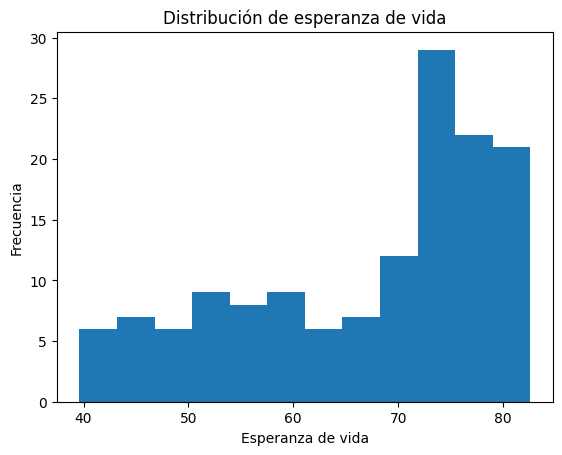

Interpretación: la mayoría de los países se concentra entre 65 y 80 años de esperanza de vida,
con una cola hacia valores bajos (países africanos principalmente).


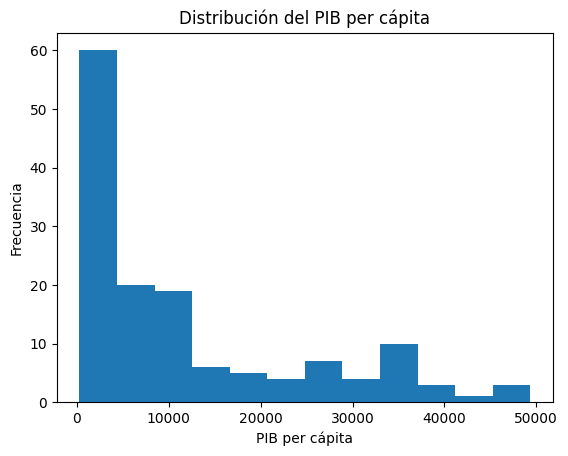

Interpretación: distribución fuertemente sesgada a la derecha; la mayoría de los países tiene
PIB per cápita bajo y unos pocos países muy ricos generan la cola larga.


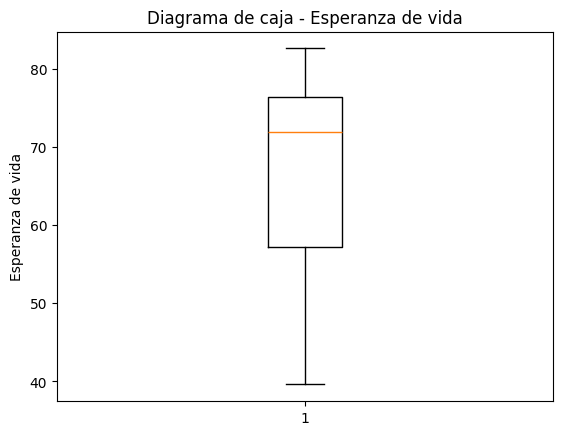

Interpretación: no se observan atípicos marcados; la caja confirma una distribución razonablemente
simétrica, coherente con medias y medianas similares.


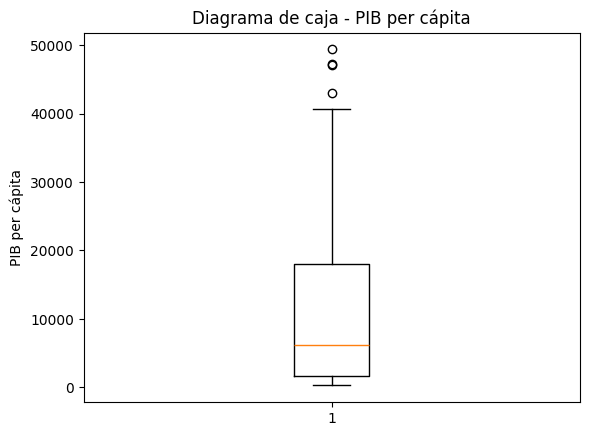

Interpretación: se observan varios puntos atípicos por encima del bigote superior,
confirmando los países de PIB per cápita extremo detectados con la regla 1.5*IQR.


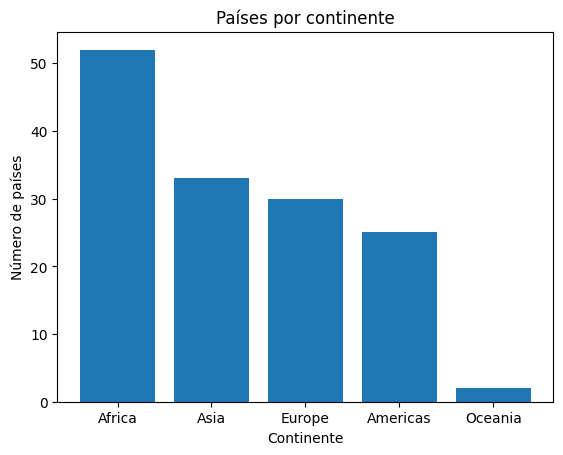

Interpretación: África concentra la mayor cantidad de países en el dataset, seguida de Asia,
Europa y América; Oceanía tiene muy pocos países representados.


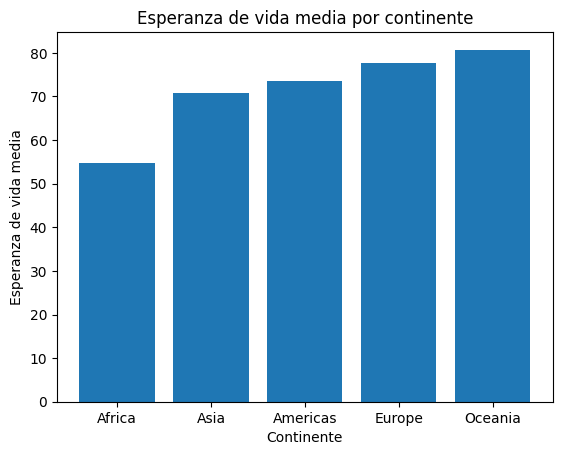

Interpretación: Oceanía y Europa tienen la mayor esperanza de vida media; África presenta
la más baja, reflejando desigualdades estructurales entre continentes.


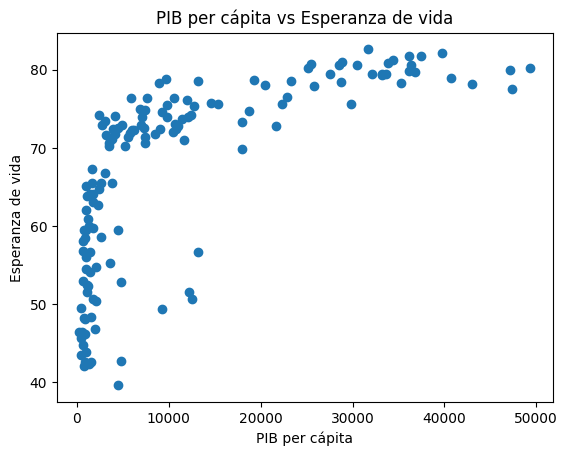

Interpretación: se observa una relación positiva no lineal (tipo logarítmica): la esperanza de
vida aumenta rápidamente con el PIB per cápita en niveles bajos, y se estabiliza en niveles altos.


In [6]:
plt.figure()
plt.hist(dfp["lifeExp"], bins=12)
plt.xlabel("Esperanza de vida"); plt.ylabel("Frecuencia")
plt.title("Distribución de esperanza de vida"); plt.show()
print("Interpretación: la mayoría de los países se concentra entre 65 y 80 años de esperanza de vida,\n"
      "con una cola hacia valores bajos (países africanos principalmente).")

plt.figure()
plt.hist(dfp["gdpPercap"], bins=12)
plt.xlabel("PIB per cápita"); plt.ylabel("Frecuencia")
plt.title("Distribución del PIB per cápita"); plt.show()
print("Interpretación: distribución fuertemente sesgada a la derecha; la mayoría de los países tiene\n"
      "PIB per cápita bajo y unos pocos países muy ricos generan la cola larga.")

plt.figure()
plt.boxplot(dfp["lifeExp"], vert=True)
plt.ylabel("Esperanza de vida")
plt.title("Diagrama de caja - Esperanza de vida"); plt.show()
print("Interpretación: no se observan atípicos marcados; la caja confirma una distribución razonablemente\n"
      "simétrica, coherente con medias y medianas similares.")

plt.figure()
plt.boxplot(dfp["gdpPercap"], vert=True)
plt.ylabel("PIB per cápita")
plt.title("Diagrama de caja - PIB per cápita"); plt.show()
print("Interpretación: se observan varios puntos atípicos por encima del bigote superior,\n"
      "confirmando los países de PIB per cápita extremo detectados con la regla 1.5*IQR.")

c = dfp["continent"].value_counts()
plt.figure()
plt.bar(c.index, c.values)
plt.xlabel("Continente"); plt.ylabel("Número de países")
plt.title("Países por continente"); plt.show()
print("Interpretación: África concentra la mayor cantidad de países en el dataset, seguida de Asia,\n"
      "Europa y América; Oceanía tiene muy pocos países representados.")

m = dfp.groupby("continent")["lifeExp"].mean().sort_values()
plt.figure()
plt.bar(m.index, m.values)
plt.xlabel("Continente"); plt.ylabel("Esperanza de vida media")
plt.title("Esperanza de vida media por continente"); plt.show()
print("Interpretación: Oceanía y Europa tienen la mayor esperanza de vida media; África presenta\n"
      "la más baja, reflejando desigualdades estructurales entre continentes.")

plt.figure()
plt.scatter(dfp["gdpPercap"], dfp["lifeExp"])
plt.xlabel("PIB per cápita"); plt.ylabel("Esperanza de vida")
plt.title("PIB per cápita vs Esperanza de vida"); plt.show()
print("Interpretación: se observa una relación positiva no lineal (tipo logarítmica): la esperanza de\n"
      "vida aumenta rápidamente con el PIB per cápita en niveles bajos, y se estabiliza en niveles altos.")


# 7. Probabilidades marginales

Defina:
- A = `nivel_vida == "Alta"`
- B = pertenecer a un continente seleccionado.

Seleccione un continente y justifique su elección.

Calcule `P(A)` y `P(B)`. Presente los resultados en porcentaje y mediante un gráfico.

P(A) = 50.00%   (probabilidad de nivel de vida alto)
P(B) = 21.13%   (probabilidad de pertenecer a Europe)


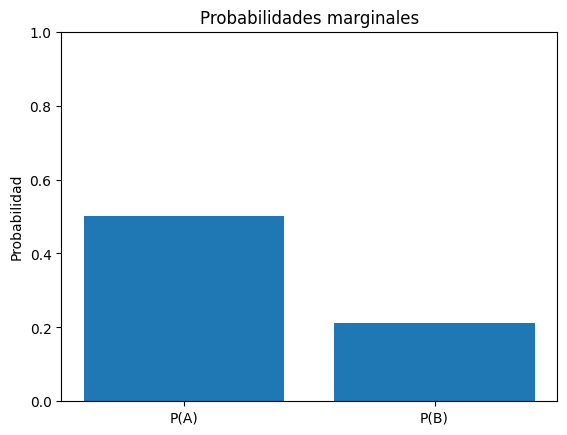


Interpretación: por construcción (mediana de lifeExp), P(A) es cercana al 50%. P(B) refleja
la proporción de países europeos dentro del total de países del año seleccionado.



In [7]:
continente_elegido = "Europe"  # Se elige Europa por ser un continente con alto nivel de vida
                                # y buen número de países, útil para contrastar con el resto.

A = dfp["nivel_vida"] == "Alta"
B = dfp["continent"] == continente_elegido

pA = A.mean()
pB = B.mean()

print(f"P(A) = {pA:.2%}   (probabilidad de nivel de vida alto)")
print(f"P(B) = {pB:.2%}   (probabilidad de pertenecer a {continente_elegido})")

s = pd.Series({"P(A)": pA, "P(B)": pB})
plt.figure()
plt.bar(s.index, s.values)
plt.ylim(0, 1); plt.ylabel("Probabilidad")
plt.title("Probabilidades marginales")
plt.show()

print("""
Interpretación: por construcción (mediana de lifeExp), P(A) es cercana al 50%. P(B) refleja
la proporción de países europeos dentro del total de países del año seleccionado.
""")


# 8. Probabilidad conjunta

Calcule:

`P(A ∩ B)`

Es decir, la probabilidad de seleccionar un país que tenga nivel de vida alto y pertenezca al continente seleccionado.

Construya una tabla de contingencia y un gráfico.

continent,Africa,Americas,Asia,Europe,Oceania
nivel_vida,,,,,
Alta,5,17,18,29,2
Baja,47,8,15,1,0


P(A ∩ B) = 20.42%


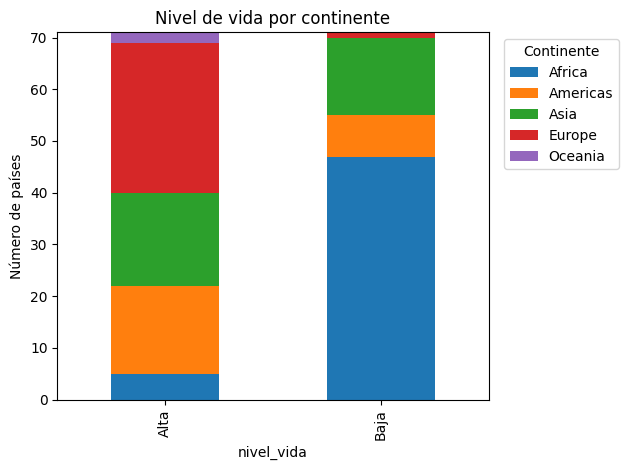


Interpretación: P(A ∩ B) = 20.42% representa la proporción de TODOS los países del dataset que
cumplen simultáneamente las dos condiciones: tener nivel de vida alto Y pertenecer a Europe.
La tabla de contingencia muestra que casi todos los países europeos tienen nivel de vida alto,
mientras que la mayoría de los africanos tiene nivel de vida bajo.



In [8]:
tabla = pd.crosstab(dfp["nivel_vida"], dfp["continent"])
display(tabla)

pAB = (A & B).mean()
print(f"P(A ∩ B) = {pAB:.2%}")

plt.figure()
tabla.plot(kind="bar", stacked=True, ax=plt.gca())
plt.ylabel("Número de países")
plt.title(f"Nivel de vida por continente")
plt.legend(title="Continente", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"""
Interpretación: P(A ∩ B) = {pAB:.2%} representa la proporción de TODOS los países del dataset que
cumplen simultáneamente las dos condiciones: tener nivel de vida alto Y pertenecer a {continente_elegido}.
La tabla de contingencia muestra que casi todos los países europeos tienen nivel de vida alto,
mientras que la mayoría de los africanos tiene nivel de vida bajo.
""")


# 9. Probabilidad condicional

Calcule:

`P(A | B)`

Interprete la probabilidad de que un país tenga nivel de vida alto dado que pertenece al continente seleccionado.

Compare `P(A|B)` con `P(A)`.

P(A | B) = 96.67%
P(A) = 50.00%


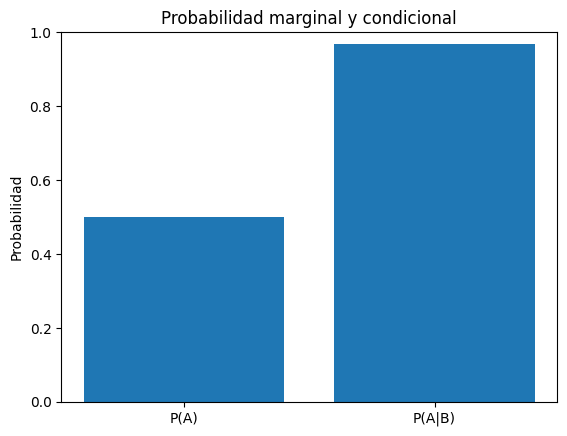


Interpretación: P(A|B) = 96.67% es mucho mayor que P(A) = 50.00%. Esto significa que
saber que un país pertenece a Europe aumenta fuertemente la probabilidad de que tenga
nivel de vida alto, comparado con la probabilidad general. Es decir, A y B NO son independientes.



In [9]:
pA_dado_B = pAB / pB
print(f"P(A | B) = {pA_dado_B:.2%}")
print(f"P(A) = {pA:.2%}")

s = pd.Series({"P(A)":pA, "P(A|B)":pA_dado_B})
plt.figure()
plt.bar(s.index, s.values)
plt.ylim(0,1); plt.ylabel("Probabilidad")
plt.title("Probabilidad marginal y condicional"); plt.show()

print(f"""
Interpretación: P(A|B) = {pA_dado_B:.2%} es mucho mayor que P(A) = {pA:.2%}. Esto significa que
saber que un país pertenece a {continente_elegido} aumenta fuertemente la probabilidad de que tenga
nivel de vida alto, comparado con la probabilidad general. Es decir, A y B NO son independientes.
""")


# 10. Teorema de Bayes

Invierta la pregunta:

> Si se selecciona un país con nivel de vida alto, ¿cuál es la probabilidad de que pertenezca al continente seleccionado?

Calcule:

`P(B|A) = P(A|B)P(B) / P(A)`

Identifique:
- prior: `P(B)`;
- verosimilitud: `P(A|B)`;
- evidencia: `P(A)`;
- posterior: `P(B|A)`.

Valide el resultado mediante cálculo directo.

Prior P(B) = 0.2113
Verosimilitud P(A|B) = 0.9667
Evidencia P(A) = 0.5000
Posterior P(B|A), Bayes = 0.4085
Posterior P(B|A), directa = 0.4085


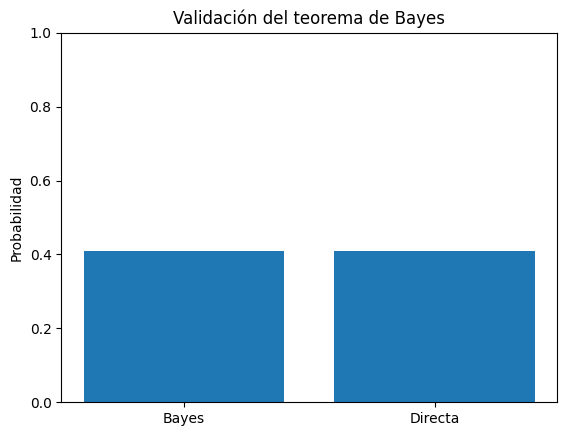


Interpretación: el cálculo por el teorema de Bayes (0.4085) coincide con el cálculo
directo (0.4085), lo que valida el resultado. Significa que si se elige al azar un
país con nivel de vida alto, hay aproximadamente un 40.8% de probabilidad de que sea
de Europe.



In [10]:
pB_dado_A_bayes = (pA_dado_B * pB) / pA
pB_dado_A_directa = (A & B).sum() / A.sum()

print(f"Prior P(B) = {pB:.4f}")
print(f"Verosimilitud P(A|B) = {pA_dado_B:.4f}")
print(f"Evidencia P(A) = {pA:.4f}")
print(f"Posterior P(B|A), Bayes = {pB_dado_A_bayes:.4f}")
print(f"Posterior P(B|A), directa = {pB_dado_A_directa:.4f}")

s = pd.Series({"Bayes":pB_dado_A_bayes, "Directa":pB_dado_A_directa})
plt.figure()
plt.bar(s.index, s.values)
plt.ylim(0,1); plt.ylabel("Probabilidad")
plt.title("Validación del teorema de Bayes"); plt.show()

print(f"""
Interpretación: el cálculo por el teorema de Bayes ({pB_dado_A_bayes:.4f}) coincide con el cálculo
directo ({pB_dado_A_directa:.4f}), lo que valida el resultado. Significa que si se elige al azar un
país con nivel de vida alto, hay aproximadamente un {pB_dado_A_bayes:.1%} de probabilidad de que sea
de {continente_elegido}.
""")


# 11. Segunda investigación probabilística

El equipo debe formular una segunda pregunta de investigación.

Cree una variable categórica `PIB_nivel` usando la mediana de `gdpPercap`:
- Alto;
- Bajo.

Luego seleccione dos eventos y calcule:
1. probabilidades marginales;
2. probabilidad conjunta;
3. probabilidad condicional;
4. teorema de Bayes;
5. una comparación con cálculo directo;
6. al menos dos gráficos.

Ejemplo de pregunta:

**¿Cuál es la probabilidad de que un país tenga PIB per cápita alto dado que pertenece a un continente determinado?**

El equipo debe documentar y justificar su propia pregunta.

P(C) = 50.00%   (PIB per cápita alto)
P(D) = 23.24%   (pertenecer a Asia)


continent,Africa,Americas,Asia,Europe,Oceania
PIB_nivel,,,,,
Alto,9,17,14,29,2
Bajo,43,8,19,1,0


P(C ∩ D) = 9.86%
P(C | D) = 42.42%
P(D | C) Bayes = 0.1972   Directa = 0.1972


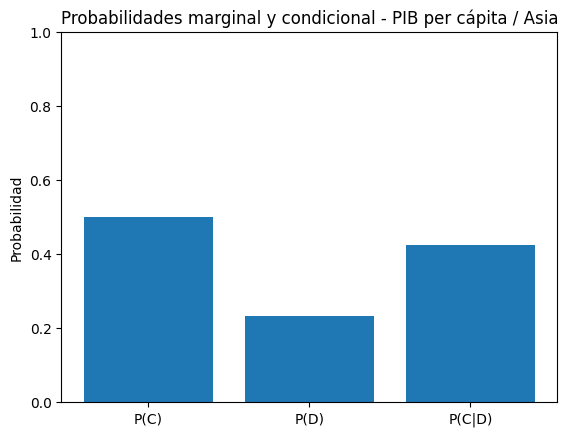

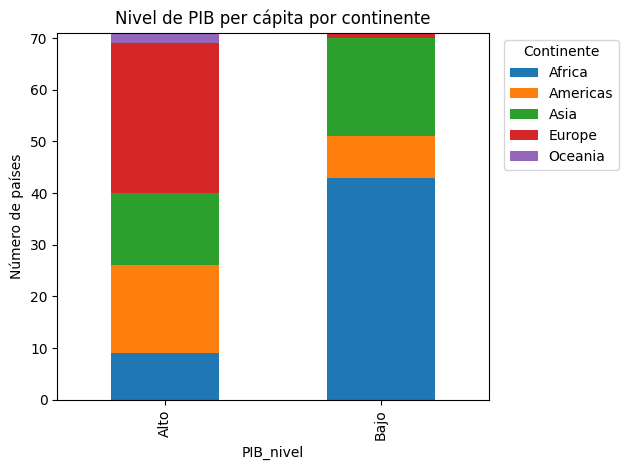


Interpretación: P(C|D) = 42.42% frente a P(C) = 50.00% muestra que pertenecer a Asia
reduce la probabilidad de tener PIB per cápita alto respecto al
promedio general, aunque en menor medida que lo observado con Europa y nivel de vida. La validación
de Bayes coincide con el cálculo directo (0.1972 = 0.1972).



In [11]:
mediana_pib = dfp["gdpPercap"].median()
dfp["PIB_nivel"] = np.where(dfp["gdpPercap"] >= mediana_pib, "Alto", "Bajo")

# Pregunta de investigación: ¿Cuál es la probabilidad de que un país tenga PIB per cápita
# alto dado que pertenece a Asia? Se elige Asia por ser un continente con gran heterogeneidad
# económica (desde economías emergentes hasta países de ingresos muy bajos), lo que la hace
# interesante para contrastar con el resultado del continente europeo analizado antes.

continente_2 = "Asia"
C = dfp["PIB_nivel"] == "Alto"
D = dfp["continent"] == continente_2

# 1) Probabilidades marginales
pC = C.mean()
pD = D.mean()
print(f"P(C) = {pC:.2%}   (PIB per cápita alto)")
print(f"P(D) = {pD:.2%}   (pertenecer a {continente_2})")

# 2) Probabilidad conjunta
tabla2 = pd.crosstab(dfp["PIB_nivel"], dfp["continent"])
display(tabla2)
pCD = (C & D).mean()
print(f"P(C ∩ D) = {pCD:.2%}")

# 3) Probabilidad condicional
pC_dado_D = pCD / pD
print(f"P(C | D) = {pC_dado_D:.2%}")

# 4) Teorema de Bayes
pD_dado_C_bayes = (pC_dado_D * pD) / pC
# 5) Comparación con cálculo directo
pD_dado_C_directa = (C & D).sum() / C.sum()
print(f"P(D | C) Bayes = {pD_dado_C_bayes:.4f}   Directa = {pD_dado_C_directa:.4f}")

# 6) Gráficos (al menos dos)
plt.figure()
s1 = pd.Series({"P(C)":pC, "P(D)":pD, "P(C|D)":pC_dado_D})
plt.bar(s1.index, s1.values)
plt.ylim(0,1); plt.ylabel("Probabilidad")
plt.title("Probabilidades marginal y condicional - PIB per cápita / Asia")
plt.show()

plt.figure()
tabla2.plot(kind="bar", stacked=True, ax=plt.gca())
plt.ylabel("Número de países")
plt.title("Nivel de PIB per cápita por continente")
plt.legend(title="Continente", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"""
Interpretación: P(C|D) = {pC_dado_D:.2%} frente a P(C) = {pC:.2%} muestra que pertenecer a Asia
{"aumenta" if pC_dado_D>pC else "reduce"} la probabilidad de tener PIB per cápita alto respecto al
promedio general, aunque en menor medida que lo observado con Europa y nivel de vida. La validación
de Bayes coincide con el cálculo directo ({pD_dado_C_bayes:.4f} = {pD_dado_C_directa:.4f}).
""")


# 12. Informe técnico final

## 12.1 Introducción
El propósito de este análisis es aplicar estadística descriptiva y probabilidad para caracterizar
diferencias en desarrollo humano y económico entre países, usando herramientas de Python. El
contexto es apoyar la toma de decisiones de una organización interesada en identificar patrones
de bienestar y riqueza a nivel mundial.

## 12.2 Fuente de datos
- **Nombre:** Gapminder (subconjunto de 5 años, distribuido por Plotly).
- **URL:** https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv
- **Fecha de consulta:** 26 de septiembre de 2026.
- **Número de registros totales:** 1704 filas (12 años × 142 países).
- **Registros analizados (año 2007):** 142 países.
- **Variables:** country, continent, year, lifeExp, pop, gdpPercap.

## 12.3 Identificación y selección de variables
| Variable | Tipo | Descripción | Seleccionada | Justificación |
|---|---|---|---|---|
| country | Cualitativa nominal | Nombre del país | Sí | Identificador de la unidad de análisis |
| continent | Cualitativa nominal | Continente | Sí | Variable de agrupación para comparar regiones |
| year | Cuantitativa discreta | Año de observación | Sí (para filtrar) | Permite fijar un corte temporal (2007) |
| lifeExp | Cuantitativa continua | Esperanza de vida al nacer | Sí | Indicador de bienestar/desarrollo humano |
| pop | Cuantitativa discreta | Población total | Sí | Contextualiza el tamaño del país |
| gdpPercap | Cuantitativa continua | PIB per cápita | Sí | Indicador económico central del análisis |
| nivel_vida (derivada) | Cualitativa nominal | Alta/Baja según mediana de lifeExp | Sí | Variable binaria para el análisis probabilístico |
| PIB_nivel (derivada) | Cualitativa nominal | Alto/Bajo según mediana de gdpPercap | Sí | Segunda variable binaria para la segunda investigación |

No hay valores faltantes ni duplicados en el dataset original.

## 12.4 Análisis descriptivo
- **Tendencia central:** la esperanza de vida (media ≈ 67 años, mediana ≈ 72 años) es razonablemente
  simétrica. El PIB per cápita y la población muestran medias muy superiores a sus medianas
  (11 680 vs. 6 124 USD, y 44,0 millones vs. 10,5 millones de habitantes), evidenciando distribuciones
  sesgadas a la derecha por la presencia de países muy ricos o muy poblados.
- **Dispersión:** el coeficiente de variación de lifeExp es bajo (~18%), mientras que gdpPercap y pop
  superan el 100%, confirmando alta heterogeneidad económica y demográfica entre países. Se usó la
  convención muestral (ddof=1) de forma consistente.
- **Posición y atípicos:** el IQR de gdpPercap es amplio (≈16 384 USD). Con la regla 1.5×IQR se
  detectaron 4 países atípicos por PIB per cápita extremadamente alto; no se detectaron atípicos
  por abajo, dado que el PIB no toma valores negativos.

## 12.5 Análisis probabilístico
- **Marginales:** P(nivel de vida alto) = 50% (por construcción, según la mediana); P(pertenecer a
  Europa) ≈ 21.1%.
- **Conjunta:** P(nivel alto ∩ Europa) ≈ 20.4%.
- **Condicional:** P(nivel alto | Europa) ≈ 96.7%, muy superior al 50% marginal, lo que indica una
  fuerte asociación positiva entre pertenecer a Europa y tener nivel de vida alto.
- **Bayes:** P(Europa | nivel alto) ≈ 40.9%, calculado tanto por la fórmula de Bayes como de forma
  directa, con resultados idénticos, validando el cálculo.
- **Segunda investigación (PIB per cápita vs. Asia):** P(PIB alto | Asia) ≈ 42.4% frente a P(PIB alto)
  = 50%, es decir, pertenecer a Asia reduce levemente la probabilidad de tener PIB per cápita alto
  respecto al promedio mundial, a diferencia de lo observado con Europa y nivel de vida. La validación
  de Bayes también coincidió con el cálculo directo (≈19.7% en ambos casos).

## 12.6 Visualización
Los histogramas muestran la forma de las distribuciones (simétrica para lifeExp, sesgada para
gdpPercap). Los diagramas de caja confirman la ausencia de atípicos en lifeExp y su presencia en
gdpPercap. El gráfico de barras por continente muestra que África concentra más países que
cualquier otro continente en el dataset. El gráfico de dispersión gdpPercap vs. lifeExp revela una
relación positiva no lineal (de tipo logarítmico), consistente con la literatura de desarrollo
económico.

## 12.7 Hallazgos
1. La esperanza de vida mundial en 2007 tiene una distribución razonablemente simétrica, con media
   y mediana cercanas (~67 y ~72 años).
2. El PIB per cápita está fuertemente sesgado a la derecha: la mayoría de los países tiene ingresos
   bajos, mientras un pequeño grupo concentra ingresos muy altos.
3. Existe una relación clara entre continente y nivel de vida: pertenecer a Europa incrementa la
   probabilidad de tener nivel de vida alto de 50% a casi 97%.
4. La probabilidad de que un país con nivel de vida alto sea europeo es de aproximadamente 41%,
   por lo que la mayoría de los países con nivel de vida alto proviene de otros continentes.
5. Se detectaron 4 países atípicos por PIB per cápita extremadamente elevado, lo que sugiere
   economías particulares (por ejemplo, productoras de petróleo o centros financieros).
6. África concentra la mayor cantidad de países del dataset y presenta la esperanza de vida media
   más baja entre los continentes.
7. La relación entre PIB per cápita y esperanza de vida no es lineal: los incrementos de ingreso
   generan mayores ganancias de esperanza de vida en niveles bajos de PIB que en niveles altos.
8. La asociación entre PIB alto y pertenecer a Asia es más débil (42.4% vs. 50% esperado) que la
   asociación entre nivel de vida alto y pertenecer a Europa, lo que indica mayor heterogeneidad
   económica dentro del continente asiático.

## 12.8 Conclusiones
El análisis descriptivo evidencia fuertes desigualdades económicas y de esperanza de vida entre
países y continentes. El análisis probabilístico muestra una asociación clara (no necesariamente
causal) entre continente y nivel de vida: no se puede afirmar que "ser europeo cause" un nivel de
vida alto, solo que ambos eventos están fuertemente correlacionados en los datos analizados. Los
objetivos general y específicos se cumplieron: se identificaron y justificaron variables, se
calcularon medidas estadísticas y probabilísticas, y se generaron visualizaciones interpretadas.

## 12.9 Limitaciones
- La fuente corresponde a un subconjunto de Gapminder con datos hasta 2007; no refleja la situación
  actual (2026).
- El análisis se basa en un único año (2007); no se estudian tendencias temporales.
- Las variables son agregadas a nivel país, lo que oculta desigualdades internas.
- Las variables binarias (nivel_vida, PIB_nivel) se construyeron con la mediana del propio año
  seleccionado, lo cual es útil para comparar dentro del dataset, pero es una convención arbitraria
  y no un umbral internacional estándar.
- El tamaño de muestra por continente es desigual (por ejemplo, Oceanía solo tiene 2 países), lo que
  limita la robustez estadística de las comparaciones para ese continente.


# 13. Entregables y rúbrica

### Entregables
- Notebook `.ipynb` ejecutable.
- Fuente externa documentada.
- Matriz de variables.
- Cálculos estadísticos.
- Cálculos probabilísticos.
- Gráficos.
- Informe y conclusiones.

### Rúbrica sugerida

| Criterio | Peso |
|---|---:|
| Fuente, carga y exploración de datos | 10% |
| Identificación y selección de variables | 10% |
| Tendencia central | 10% |
| Dispersión | 10% |
| Posición y atípicos | 10% |
| Probabilidades marginal y conjunta | 10% |
| Probabilidad condicional | 10% |
| Teorema de Bayes y validación | 10% |
| Visualización e interpretación | 10% |
| Informe y conclusiones | 10% |
| **Total** | **100%** |

### Lista de comprobación
- [ ] Fuente externa documentada.
- [ ] Variables identificadas y clasificadas.
- [ ] Variables seleccionadas y justificadas.
- [ ] Tendencia central calculada.
- [ ] Dispersión calculada.
- [ ] Posición y atípicos analizados.
- [ ] Probabilidad marginal calculada.
- [ ] Probabilidad conjunta calculada.
- [ ] Probabilidad condicional calculada.
- [ ] Bayes aplicado y validado.
- [ ] Gráficos generados.
- [ ] Resultados interpretados.
- [ ] Informe y conclusiones incluidos.
- [ ] Notebook ejecutable de principio a fin.

# 14. Referencia técnica

Pandas permite cargar archivos CSV mediante `read_csv`, incluyendo fuentes externas accesibles mediante URL.

Documentación: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

**Nota de reproducibilidad:** si la fuente externa cambia o deja de estar disponible, registre la fecha de consulta y documente cualquier modificación realizada al código.